01 class imbalance: why ScoNet-MT almost never says "neutral"

in my reproduction ScoNet-MT@16k gets 98.5% of the negatives right but only **40.5% of the neutrals**, and 97% of the missed neutrals are called negative. in the old notebook 03 i found that the model *can* rank neutral above negative (AUC 0.95), so the problem is where the decision border sits, not missing features.

in this notebook i want to understand from zero **why** a class imbalance moves the border, and compare the usual fixes. in step 1 i check how unbalanced Scoliosis1K really is (all 4 splits), in step 2 what a training batch of ScoNet-MT looks like, in step 3 why a rare class loses at the border (with a small example i can compute by hand), in step 4 the 4 usual fixes written as formulas, in step 5 the 4 fixes on a toy dataset where i know the truth, in step 6 the fix "post-hoc logit adjustment" on my real ScoNet-MT logits, in step 7 the fixes in a mini training on real silhouettes, and step 8 is the analysis.

In [1]:
import sys
import os
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

sys.path.insert(0, os.path.abspath(os.path.join('..', 'tools')))
from common import *

FIG_DIR = os.path.join('output', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)


def save_and_show(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=120)
    plt.show()


print('device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')

device: cuda NVIDIA GeForce RTX 3050 Laptop GPU


step 1: how unbalanced is Scoliosis1K?

every split file has a `TRAIN_SET` and a `TEST_SET` (subject ids), and the class is the folder name inside the subject folder. i count both sets for the 4 official ratios (positive : neutral : negative = 1:1:2, 1:1:4, 1:1:8, 1:1:16). our paper uses **1:1:8**.

In [2]:
counts = {}
for ratio in ['112', '114', '118', '1116']:
    split = load_split(ratio)
    for part in ['TRAIN_SET', 'TEST_SET']:
        by_class = children_by_class(split[part])
        counts[(ratio, part)] = [len(by_class[c]) for c in LABEL_NAMES]

print(f'{"split":6s} | {"train neg / neu / pos":>24s} | {"neg per neutral":>15s} | {"test neg / neu / pos":>22s}')
for ratio in ['112', '114', '118', '1116']:
    tr, te = counts[(ratio, 'TRAIN_SET')], counts[(ratio, 'TEST_SET')]
    print(f'1:1:{ratio[2:]:3s} | {tr[0]:8d} / {tr[1]:4d} / {tr[2]:4d}  | {tr[0] / tr[1]:15.1f} | {te[0]:6d} / {te[1]:4d} / {te[2]:4d}')

train_counts = np.array(counts[('118', 'TRAIN_SET')])
prior = train_counts / train_counts.sum()
print()
print('1:1:8 train prior (negative, neutral, positive):', np.round(prior, 3))

split  |    train neg / neu / pos | neg per neutral |   test neg / neu / pos
1:1:2   |      373 /  186 /  186  |             2.0 |    427 /   14 /  307
1:1:4   |      497 /  124 /  124  |             4.0 |    303 /   76 /  369
1:1:8   |      596 /   74 /   74  |             8.1 |    204 /  126 /  419
1:1:16  |      663 /   41 /   41  |            16.2 |    137 /  159 /  452

1:1:8 train prior (negative, neutral, positive): [0.801 0.099 0.099]


in our split (1:1:8) the training set has **596 / 74 / 74**, so about **8 negatives for every neutral**, and the prior is 0.80 / 0.10 / 0.10. the test set is unbalanced in the *other* direction, 204 / 126 / 419, mostly positive. so a model that learned "most children are negative" in training is then tested on children that are mostly not negative.

the other ratios are not just "more or less imbalance": in 1:1:2 the test set has only **14 neutrals**, and in 1:1:16 the training set has only 41. so the results on different ratios also differ in how many neutrals they test, not only in the imbalance.

step 2: what does one training batch look like?

the ScoNet config uses OpenGait's `TripletSampler` with `batch_size [8, 8]`: **8 random children**, and 8 copies of each (different random frames). the class is not used to pick the children, so the batch has the same class mix as the training set.

i simulate 20,000 batches and count the neutral children in each. the exact number of batches without any neutral child can also be computed by hand: picking 8 of 744 children without any of the 74 neutrals is `C(670, 8) / C(744, 8)`. TG-MILNet's group uses a different sampler in their public DRF baseline config (`DiseaseTripletSampler`, `batch_size [3, 22]`), with **22 children of every class** in every batch, so every batch is balanced.

natural sampler (8 children):
  mean children per batch neg / neu / pos: [6.41 0.8  0.79]
  batches with NO neutral child: simulated 43.1 % | exact 43.1 %
  batches with NO positive child: 43.1 %
balanced sampler [3, 22]: always 22 / 22 / 22 -> 0 % batches without neutral

in 16,000 iterations, one child is drawn on average: 172.0 times (natural, any class)
                       balanced [3, 22]: one negative 590.6 times, one neutral 4756.8 times


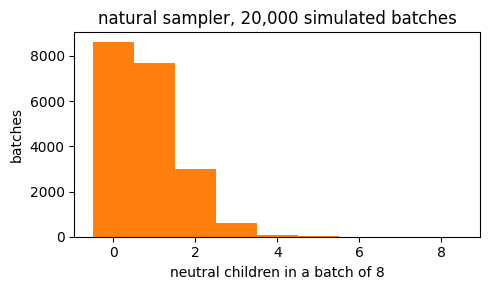

In [3]:
train_by_class = children_by_class(load_split('118')['TRAIN_SET'])
train_labels = np.array([c for c in range(3) for _ in train_by_class[LABEL_NAMES[c]]])


def simulate_natural(n_batches=20000, n_children=8, seed=0):
    rng = np.random.default_rng(seed)
    per_batch = np.zeros((n_batches, 3), dtype=int)
    for b in range(n_batches):
        chosen = rng.choice(len(train_labels), n_children, replace=False)
        for c in range(3):
            per_batch[b, c] = (train_labels[chosen] == c).sum()
    return per_batch


per_batch = simulate_natural()
exact = math.comb(int(train_counts[0] + train_counts[2]), 8) / math.comb(int(train_counts.sum()), 8)
print('natural sampler (8 children):')
print('  mean children per batch neg / neu / pos:', np.round(per_batch.mean(0), 2))
print('  batches with NO neutral child: simulated', round(100 * (per_batch[:, 1] == 0).mean(), 1), '% | exact', round(100 * exact, 1), '%')
print('  batches with NO positive child:', round(100 * (per_batch[:, 2] == 0).mean(), 1), '%')
print('balanced sampler [3, 22]: always 22 / 22 / 22 -> 0 % batches without neutral')

# how often is one neutral child seen, compared to one negative child?
print()
print('in 16,000 iterations, one child is drawn on average:', round(16000 * 8 / train_counts.sum(), 1), 'times (natural, any class)')
print('                       balanced [3, 22]: one negative', round(16000 * 22 / train_counts[0], 1),
      'times, one neutral', round(16000 * 22 / train_counts[1], 1), 'times')

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(per_batch[:, 1], bins=np.arange(10) - 0.5, color='tab:orange')
ax.set_xlabel('neutral children in a batch of 8')
ax.set_ylabel('batches')
ax.set_title('natural sampler, 20,000 simulated batches')
save_and_show(fig, '02_neutral_per_batch.png')

a batch has on average 6.4 negatives and only **0.8 neutral and 0.8 positive** children, and **43.1% of all batches have no neutral child at all** (the simulation and the exact formula agree). in those batches the neutral class only gets "push away" gradient, never "pull towards".

with the balanced `[3, 22]` sampler every batch has 22 neutrals. over 16,000 iterations one neutral child would be drawn about **4,757 times** (vs ~172 times for any child with the natural sampler). so the balanced sampler shows the same 74 neutral children again and again, and there's a risk of memorising them (step 7 shows this).

step 3: why does a rare class lose at the border?

a classifier trained with cross entropy tries to learn `p(class | x)`, and bayes' rule says

`p(class | x) = p(x | class) * p(class) / p(x)`

where `p(x | class)` is how a child of this class *looks* (the thing we want the model to learn), and `p(class)` is the **prior**, how common the class is in the training data. so the prior is baked into the answer. if neutral is 8 times rarer than negative, a neutral-looking child must look **8 times more** neutral than negative before the model says "neutral".

**a small example i can compute by hand.** one feature `x`, negatives `x ~ Normal(0, 1)` and neutrals `x ~ Normal(1.5, 1)`. the border is where both posteriors are equal:

`p(x | neu) * p(neu) = p(x | neg) * p(neg)`

if i take the log of both normal densities, the `x^2` terms cancel and what remains is

`x* = (mu_neg + mu_neu) / 2 + sigma^2 * ln(p(neg) / p(neu)) / (mu_neu - mu_neg)`

so with equal priors `x* = 0.75 + 0 = 0.75`, and with a prior of 8 : 1 (our 596 : 74) `x* = 0.75 + ln(8.05) / 1.5 = 0.75 + 1.39 = 2.14`. the neutral recall is the share of neutrals above the border, `P(x > x*)` for `Normal(1.5, 1)`, and i compute it with `math.erf`.

AUC neutral vs negative in this example: 0.856 (the same for every border)

 prior neg : neu | border x* | neutral recall | negative recall
        1.00 : 1 |      0.75 |          77.3% |           77.3%
        2.00 : 1 |      1.21 |          61.3% |           88.7%
        4.00 : 1 |      1.67 |          43.1% |           95.3%
        8.05 : 1 |      2.14 |          26.1% |           98.4%
       16.00 : 1 |      2.60 |          13.6% |           99.5%


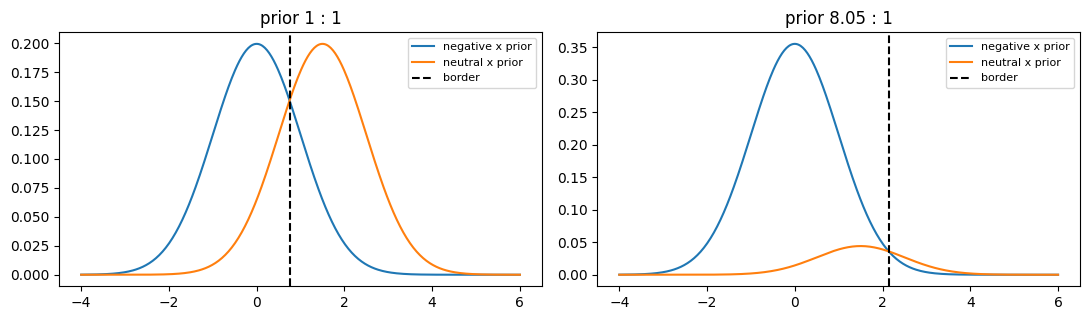

In [4]:
def normal_cdf(x, mu=0.0, sigma=1.0):
    return 0.5 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))


def border(mu_neg, mu_neu, sigma, prior_neg, prior_neu):
    return (mu_neg + mu_neu) / 2 + sigma ** 2 * math.log(prior_neg / prior_neu) / (mu_neu - mu_neg)


mu_neg, mu_neu, sigma = 0.0, 1.5, 1.0
toy_auc = normal_cdf((mu_neu - mu_neg) / (sigma * math.sqrt(2)))      # AUC of two normals
print('AUC neutral vs negative in this example:', round(toy_auc, 3), '(the same for every border)')
print()
print(f'{"prior neg : neu":>16s} | {"border x*":>9s} | {"neutral recall":>14s} | {"negative recall":>15s}')
for ratio in [1, 2, 4, 8.05, 16]:
    x_star = border(mu_neg, mu_neu, sigma, ratio, 1)
    rec_neu = 1 - normal_cdf(x_star, mu_neu, sigma)
    rec_neg = normal_cdf(x_star, mu_neg, sigma)
    print(f'{ratio:>12.2f} : 1 | {x_star:9.2f} | {100 * rec_neu:13.1f}% | {100 * rec_neg:14.1f}%')

xs = np.linspace(-4, 6, 400)
pdf = lambda x, mu: np.exp(-(x - mu) ** 2 / 2) / np.sqrt(2 * np.pi)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for a, ratio in zip(ax, [1, 8.05]):
    p_neg, p_neu = ratio / (ratio + 1), 1 / (ratio + 1)
    a.plot(xs, pdf(xs, mu_neg) * p_neg, label='negative x prior')
    a.plot(xs, pdf(xs, mu_neu) * p_neu, label='neutral x prior')
    a.axvline(border(mu_neg, mu_neu, sigma, ratio, 1), color='k', ls='--', label='border')
    a.set_title(f'prior {ratio:g} : 1')
    a.legend(fontsize=8)
save_and_show(fig, '03_bayes_border.png')

the AUC in the example is **0.856**, and it stays the same for every border: the prior doesn't change how well the classes can be *ranked*, only where the cut is. with equal priors the border sits in the middle (0.75) and both recalls are 77.3%. **with our 8 : 1 prior the border moves to 2.14, the neutral recall falls to 26.1% and the negative recall goes up to 98.4%.** that's very close to my real ScoNet-MT (neutral 40.5 / negative 98.5), so the pattern of my model is exactly what bayes' rule predicts for an 8 : 1 prior, no "bad features" are needed to explain it. at 16 : 1 the neutral recall would be 13.6%, and this is why every paper collapses at 1:1:16.

step 4: the 4 usual fixes, as formulas

let `z` be the logits of a child (for ScoNet: 16 x the mean BNNeck cosine over strips), `pi_c` the training prior of class `c`, and `tau` a strength (usually 1).

| fix | what changes | formula | who uses it |
|---|---|---|---|
| **a. weighted CE** | the loss | `loss = w_y * CE(z, y)`, `w_c` = 1 / count_c (normalised) | ScoliGaitX ("inverse class-weighted CE"); TG-MILNet group's DRF config `class_weight [0.174, 1.413, 1.413]` |
| **b. balanced sampler** | the batch | every batch has the same number of children per class | TG-MILNet group's DRF config (`DiseaseTripletSampler [3, 22]`) |
| **c. logit-adjusted loss** | the loss | `loss = CE(z + tau * log(pi), y)` | Menon et al. 2021 (ICLR), "Long-tail learning via logit adjustment" |
| **d. post-hoc logit adjustment** | only the test decision | `pred = argmax(z - tau * log(pi))` | Menon et al. 2021; my `exp_1/val_calibration` |

why c and d work (the idea of Menon et al.): if the model learns `z_c ~ log p(x | c) + log pi_c`, then subtracting `log pi_c` leaves `log p(x | c)`, and the border is the one for **equal** priors (`x* = 0.75` in step 3). **d** does this after training. **c** adds `log pi` *during* training, so the network itself doesn't have to learn the prior, and at test time the raw `z` already has a balanced border. **a** and **b** change how much each class counts in the loss, so the model learns as if the prior were (almost) equal.

a quick check of the weights of fix a: are the DRF config numbers simply 1 / count?

In [5]:
inv = 1 / train_counts
weights = inv / inv.mean()          # normalised so the mean weight is 1
print('1:1:8 train counts         :', train_counts)
print('1 / count, mean 1          :', np.round(weights, 3))
print('DRF config (TG-MILNet repo): [0.174 1.413 1.413]')
print()
print('log prior (used by fix c and d):', np.round(np.log(prior), 3))
print('neutral vs negative shift with tau = 1:', round(np.log(prior[0]) - np.log(prior[1]), 3),
      '= ln(', round(prior[0] / prior[1], 2), ')')

1:1:8 train counts         : [596  74  74]
1 / count, mean 1          : [0.175 1.412 1.412]
DRF config (TG-MILNet repo): [0.174 1.413 1.413]

log prior (used by fix c and d): [-0.222 -2.308 -2.308]
neutral vs negative shift with tau = 1: 2.086 = ln( 8.05 )


**the DRF config numbers are exactly `1 / count`** (0.175 / 1.412 / 1.412 vs 0.174 / 1.413 / 1.413 in the config). so TG-MILNet's group trains its baseline with inverse-frequency weights *and* a balanced sampler, and ScoliGaitX also says it uses inverse class weights, while the ScoNet-MT baseline used none of these. with `tau = 1`, logit adjustment moves the neutral-vs-negative border by `ln(8.05) = 2.09` logit units.

step 5: the 4 fixes on a toy dataset where i know the truth

before using real silhouettes i want to see the fixes work where everything is visible. so i make toy data in 2D: negative around (0, 0), neutral around (1.5, 0.8) and positive around (3, 0), all with spread 1, so they overlap a lot (like our classes). the training set is **800 / 100 / 100** (the same 8 : 1 : 1 as Scoliosis1K) and the test set **1000 / 1000 / 1000** (balanced, so every recall counts the same). the model is a small MLP (2 -> 32 -> 32 -> 3), Adam, 1500 steps, batch 64.

the variants are plain CE, (a) weighted CE, (b) balanced sampler, (c) logit-adjusted loss, and (d) plain CE + post-hoc adjustment, all with the same seed.

In [6]:
MEANS = np.array([[0.0, 0.0], [1.5, 0.8], [3.0, 0.0]])


def make_toy(n_per_class, seed):
    rng = np.random.default_rng(seed)
    x = np.concatenate([rng.normal(MEANS[c], 1.0, size=(n, 2)) for c, n in enumerate(n_per_class)])
    y = np.concatenate([np.full(n, c) for c, n in enumerate(n_per_class)])
    return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.long)


x_tr, y_tr = make_toy([800, 100, 100], seed=0)
x_te, y_te = make_toy([1000, 1000, 1000], seed=1)
toy_prior = torch.tensor([800, 100, 100], dtype=torch.float32) / 1000
log_prior = torch.log(toy_prior)


def train_toy(variant, steps=1500, seed=0):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = nn.Sequential(nn.Linear(2, 32), nn.ReLU(), nn.Linear(32, 32), nn.ReLU(), nn.Linear(32, 3))
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    weight = (1 / toy_prior) / (1 / toy_prior).mean() if variant == 'weighted CE' else None
    idx_by_class = [np.where(y_tr.numpy() == c)[0] for c in range(3)]
    for step in range(steps):
        if variant == 'balanced sampler':
            idx = np.concatenate([rng.choice(ix, 21) for ix in idx_by_class])
        else:
            idx = rng.choice(len(y_tr), 64)
        z = model(x_tr[idx])
        if variant == 'logit-adjusted loss':
            z = z + log_prior                       # tau = 1, only during training
        loss = F.cross_entropy(z, y_tr[idx], weight=weight)
        opt.zero_grad()
        loss.backward()
        opt.step()
    return model


toy_models = {}
for variant in ['plain CE', 'weighted CE', 'balanced sampler', 'logit-adjusted loss']:
    toy_models[variant] = train_toy(variant)

rows = []
toy_scores = {}
with torch.no_grad():
    for variant, model in toy_models.items():
        toy_scores[variant] = model(x_te).numpy()
    toy_scores['post-hoc adjustment'] = toy_scores['plain CE'] - log_prior.numpy()
y_np = y_te.numpy()
for variant, z in toy_scores.items():
    m = metrics(y_np, z.argmax(1))
    s = z[:, 1] - z[:, 0]
    m['auc'] = auc(s[y_np == 1], s[y_np == 0])
    rows.append((variant, m))
print_metrics(rows, 'toy test set (1000 per class)')
print()
for variant, m in rows:
    print(f'{variant:22s} AUC neutral vs negative = {m["auc"]:.3f}')

toy test set (1000 per class)
                                    acc      Sen      Spe  rec_neg  rec_neu  rec_pos      bal
plain CE                           67.8     95.7     68.3     95.7     29.1     78.5     67.8
weighted CE                        73.2     83.2     85.8     83.2     55.9     80.5     73.2
balanced sampler                   70.9     78.4     88.3     78.4     52.3     82.0     70.9
logit-adjusted loss                73.2     84.7     85.3     84.7     55.4     79.6     73.2
post-hoc adjustment                73.2     84.2     85.3     84.2     53.8     81.6     73.2

plain CE               AUC neutral vs negative = 0.878
weighted CE            AUC neutral vs negative = 0.869
balanced sampler       AUC neutral vs negative = 0.871
logit-adjusted loss    AUC neutral vs negative = 0.876
post-hoc adjustment    AUC neutral vs negative = 0.878


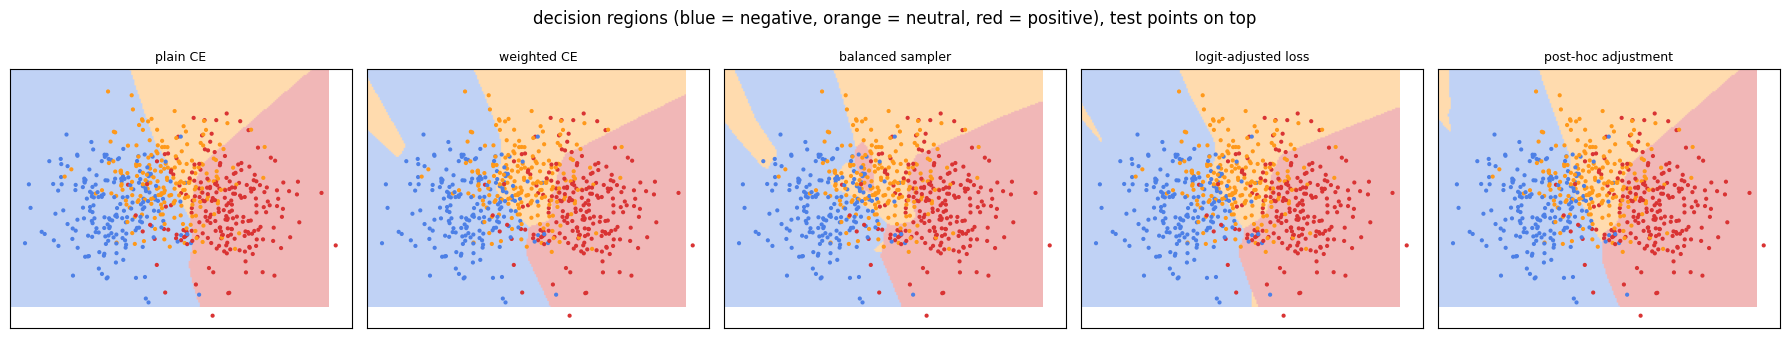

In [7]:
gx, gy = np.meshgrid(np.linspace(-3, 6, 200), np.linspace(-3, 4, 160))
grid = torch.tensor(np.stack([gx.ravel(), gy.ravel()], 1), dtype=torch.float32)
fig, ax = plt.subplots(1, 5, figsize=(18, 3.4))
colors = np.array([[0.3, 0.5, 0.9], [1.0, 0.6, 0.1], [0.85, 0.2, 0.2]])
with torch.no_grad():
    for a, variant in zip(ax, toy_scores):
        if variant == 'post-hoc adjustment':
            z = toy_models['plain CE'](grid).numpy() - log_prior.numpy()
        else:
            z = toy_models[variant](grid).numpy()
        region = z.argmax(1).reshape(gx.shape)
        a.imshow(colors[region], extent=(-3, 6, -3, 4), origin='lower', alpha=0.35, aspect='auto')
        sub = np.random.default_rng(0).choice(len(y_np), 600, replace=False)
        a.scatter(x_te[sub, 0], x_te[sub, 1], c=colors[y_np[sub]], s=4)
        a.set_title(variant, fontsize=9)
        a.set_xticks([])
        a.set_yticks([])
fig.suptitle('decision regions (blue = negative, orange = neutral, red = positive), test points on top')
save_and_show(fig, '05_toy_regions.png')

**plain CE gets neutral recall 29.1 and negative recall 95.7**, the same picture as step 3 and as my real model. **all 4 fixes raise the neutral recall to about 52-56 and the balanced accuracy from 67.8 to 71-73**, and the negative recall drops to 78-85 in exchange.

**the AUC hardly changes (0.869-0.878).** so the fixes don't make the model "see" better, they move the border. in the picture the orange (neutral) area grows into the blue area, but the shape of the classes is the same. weighted CE, logit-adjusted loss and post-hoc adjustment end up almost identical (73.2 balanced). the balanced sampler is a bit worse (70.9) and its border is the most irregular, because it repeats the same 100 neutral points very often.

step 6: post-hoc logit adjustment on my real ScoNet-MT logits

now the real model. i take the saved logits of `official@16k` (full 1:1:8 test set, 749 children), make `z = 16 * mean over strips` (the same scale as the training loss), and use

`pred = argmax(z - tau * log(prior))`, with the 1:1:8 train prior (596, 74, 74) / 744.

first a sweep over `tau` (0 = normal ScoNet). **this is chosen on the test set, so it's a curve to look at, not a result.** i also put the two competitor papers on the same Sen / Spe picture. careful with ScoliGaitX: the note under their table 3 says "Sensitivity and Specificity are wrt Negative class", so their 89.22 / 92.48 use the same convention as ScoNet-MT and TG-MILNet.

  tau |   acc   Sen   Spe |   neg   neu   pos
 0.00 |  82.6  98.5  77.8 |  98.5  40.5  87.6
 0.10 |  86.4  97.5  83.5 |  97.5  52.4  91.2
 0.20 |  88.4  95.1  87.3 |  95.1  59.5  93.8
 0.30 |  89.3  91.7  90.1 |  91.7  65.1  95.5
 0.50 |  92.0  85.8  96.5 |  85.8  82.5  97.9
 0.70 |  88.1  66.2  98.9 |  66.2  87.3  99.0
 1.00 |  79.0  31.4  99.8 |  31.4  89.7  99.0
 1.50 |  71.0   2.0 100.0 |   2.0  89.7  99.0


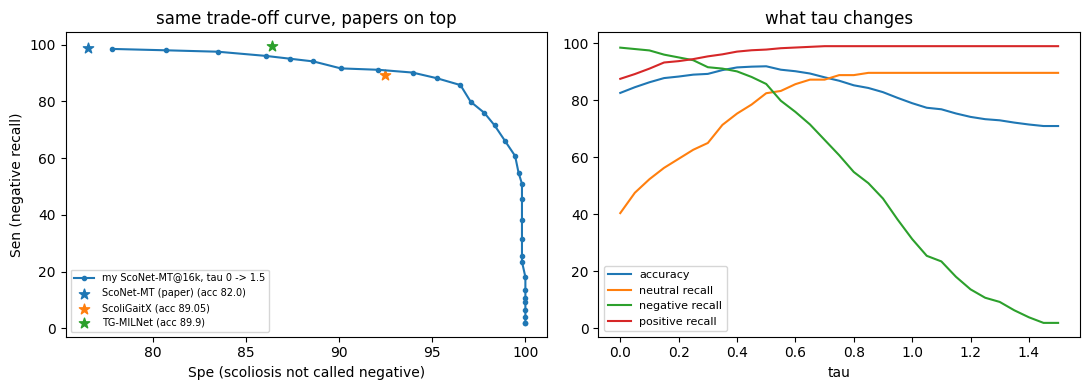

In [8]:
logits16, true, subj = load_saved_logits('official', 16000)
z16 = 16 * logits16.mean(-1)                      # [749, 3]
log_prior_real = np.log(prior)


def adjusted_pred(z, tau):
    return (z - tau * log_prior_real).argmax(1)


taus = np.round(np.arange(0, 1.51, 0.05), 2)
sweep = [metrics(true, adjusted_pred(z16, t)) for t in taus]
print(f'{"tau":>5s} | {"acc":>5s} {"Sen":>5s} {"Spe":>5s} | {"neg":>5s} {"neu":>5s} {"pos":>5s}')
for t, m in zip(taus, sweep):
    if t in (0.0, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5):
        print(f'{t:5.2f} | {m["acc"]:5.1f} {m["Sen"]:5.1f} {m["Spe"]:5.1f} | {m["rec_neg"]:5.1f} {m["rec_neu"]:5.1f} {m["rec_pos"]:5.1f}')

PAPERS = {'ScoNet-MT (paper)': (82.0, 99.0, 76.5), 'ScoliGaitX': (89.05, 89.22, 92.48), 'TG-MILNet': (89.9, 99.5, 86.4)}
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot([m['Spe'] for m in sweep], [m['Sen'] for m in sweep], '-o', ms=3, label='my ScoNet-MT@16k, tau 0 -> 1.5')
for name, (acc_, sen, spe) in PAPERS.items():
    ax[0].scatter(spe, sen, s=60, marker='*', label=f'{name} (acc {acc_})')
ax[0].set_xlabel('Spe (scoliosis not called negative)')
ax[0].set_ylabel('Sen (negative recall)')
ax[0].legend(fontsize=7)
ax[0].set_title('same trade-off curve, papers on top')
for key, label in [('acc', 'accuracy'), ('rec_neu', 'neutral recall'), ('rec_neg', 'negative recall'), ('rec_pos', 'positive recall')]:
    ax[1].plot(taus, [m[key] for m in sweep], label=label)
ax[1].set_xlabel('tau')
ax[1].legend(fontsize=8)
ax[1].set_title('what tau changes')
save_and_show(fig, '06_tau_sweep.png')

**at tau = 0.5 my ScoNet-MT@16k gets 92.0 / 85.8 / 96.5 and neutral recall 82.5.** that's a higher accuracy than ScoliGaitX (89.05) and TG-MILNet (89.9), only by moving the border of a model i already have, but it's chosen on test, so it's not a result.

in the Sen / Spe picture **ScoliGaitX lies on (just next to) my curve**: its trade-off (Sen 89.2, Spe 92.5) is what my model gives at about tau = 0.3. **TG-MILNet lies above my curve**, at Sen 99.5 my curve only reaches Spe ~78. so TG-MILNet really ranks better, while ScoliGaitX mainly chose another point on the trade-off. above tau ~0.6 it gets worse fast, the negative recall collapses (66 at 0.7, 31 at 1.0), so **tau = 1, the "theory" value, is far too strong for my model.**

honest version: choose tau without looking at the child i test

to get a number i could trust, `tau` must be chosen on children that are **not** used to measure. so here i do a 5-fold cross-validation inside the test set: i split the 749 test children into 5 parts (random, fixed seed), and for each part i choose `tau` on the other 4 parts (best balanced accuracy) and then predict only this part. at the end i put the 5 parts together and compute the metrics once.

this is still "inside the test set", so it's not a paper number (that's what the val split in `exp_1` is for), but no child is predicted with a `tau` that was chosen on itself. i do it for all 10 models (2 runs x 5 checkpoints).

In [9]:
def cv_tau(z, y, n_folds=5, seed=0):
    rng = np.random.default_rng(seed)
    fold = rng.permutation(len(y)) % n_folds
    pred = np.zeros(len(y), dtype=int)
    chosen = []
    for f in range(n_folds):
        fit, test = fold != f, fold == f
        scores = [metrics(y[fit], adjusted_pred(z[fit], t))['bal'] for t in taus]
        t_best = taus[int(np.argmax(scores))]
        chosen.append(t_best)
        pred[test] = adjusted_pred(z[test], t_best)
    return pred, chosen


rows_before, rows_after = [], []
for run in ['official', 'fromraw']:
    for it in [12000, 14000, 16000, 18000, 20000]:
        lg, y, _ = load_saved_logits(run, it)
        z = 16 * lg.mean(-1)
        pred, chosen = cv_tau(z, y)
        rows_before.append((f'{run}@{it // 1000}k  tau 0', metrics(y, z.argmax(1))))
        rows_after.append((f'{run}@{it // 1000}k  CV tau {np.round(np.mean(chosen), 2)}', metrics(y, pred)))
print_metrics(rows_before, 'normal decision (tau = 0)')
print()
print_metrics(rows_after, 'tau chosen by 5-fold CV (mean chosen tau in the name)')
print()
for key in ['acc', 'Sen', 'rec_neu', 'bal']:
    b = np.array([m[key] for _, m in rows_before])
    a = np.array([m[key] for _, m in rows_after])
    print(f'{key:8s} | tau 0: {b.mean():5.1f} +- {b.std():4.1f} | CV tau: {a.mean():5.1f} +- {a.std():4.1f}')

normal decision (tau = 0)
                                    acc      Sen      Spe  rec_neg  rec_neu  rec_pos      bal
official@12k  tau 0                82.2     95.1     81.5     95.1     65.9     80.9     80.6
official@14k  tau 0                64.1    100.0     51.4    100.0     21.4     59.4     60.3
official@16k  tau 0                82.6     98.5     77.8     98.5     40.5     87.6     75.5
official@18k  tau 0                78.6    100.0     71.6    100.0     31.0     82.6     71.2
official@20k  tau 0                76.8    100.0     69.0    100.0     31.7     79.0     70.2
fromraw@12k  tau 0                 77.6     99.5     71.7     99.5     36.5     79.2     71.8
fromraw@14k  tau 0                 53.8    100.0     36.5    100.0      4.0     46.3     50.1
fromraw@16k  tau 0                 80.4     99.5     74.5     99.5     34.9     84.7     73.1
fromraw@18k  tau 0                 78.6     99.5     71.7     99.5     34.9     81.6     72.0
fromraw@20k  tau 0                

**over the 10 models the accuracy goes from 75.0 +- 8.6 to 90.4 +- 2.0, the neutral recall from 32.5 +- 14.9 to 77.9 +- 6.6, and the balanced accuracy from 69.2 to 86.9.** the negative recall (Sen) drops from 99.2 to 87.4.

**the spread between checkpoints shrinks 4x** (accuracy std 8.6 -> 2.0), and the collapsed checkpoints come back: official@14k 64.1 -> 88.5, fromraw@14k 53.8 -> 88.3. so much of the "instability" of ScoNet-MT between checkpoints is the border jumping around, not the features. the chosen tau is between 0.21 and 0.94 (mostly 0.5-0.6) and never 1, and it differs per checkpoint, so it has to be chosen per model on validation data, not fixed.

caveat: these are CV numbers *inside* the test set (no child judged with its own tau), so they're honest about the tuning, but they're still not a val-split result. that's what `exp_1/val_calibration` is for.

step 7: the fixes in a mini training on real silhouettes

steps 5 and 6 only change the *decision*, or train a toy. here the fixes go into a real (small) ScoNet-MT training, like in the checkpoint_1 self_learning notebooks. the training children come from the 1:1:8 `TRAIN_SET`: **160 negative / 20 neutral / 20 positive** (the real 8 : 1 : 1 imbalance), and the test children from `TEST_SET`: **40 / 40 / 40** (balanced, so every recall is measured on 40 children). the ResNet9 starts from **GaitBase** weights (gait *recognition* on CASIA-B, from the OpenGait model zoo, it never saw Scoliosis1K), because from random weights 200 children are too few, and in checkpoint_1 every test child became "neutral". i train 500 iterations, Adam 1e-4, 16 frames, triplet on child id + cross entropy (ScoNet-MT), with a batch of 9 children x 2 copies (smaller than the paper's 8 x 8 because my laptop gpu has 4 GB and one run must stay under ~4 minutes).

the variants (only one thing changes each time):

| variant | sampler | loss |
|---|---|---|
| natural | random 9 children | CE |
| balanced sampler | 3 per class | CE |
| weighted CE | random 9 children | CE with weights 1 / count |
| logit-adjusted loss | random 9 children | CE on `16 z + log(pi)` |
| natural + post-hoc | (= natural model) | test: `16 z - log(pi)` |

the helpers (`train_mini`, `predict_mini`, ...) are in `tools/common.py` and are the same code as in checkpoint_1. only the loss functions are new, so they're written here.

**how the mini models are tested (important).** the models are trained on clips of 16 random frames. if i test them with all 300 frames at once, the max over frames gives much bigger values than the model ever saw in training. i checked this once on a plain ScoNet-MT mini model (same children as here): with all 300 frames it got **36.7%** (almost every child "negative"), and with 10 random 16-frame clips averaged it got **65.8%**. that's probably also why every test child became "neutral" in the checkpoint_1 self_learning notebooks. so `predict_mini` (in `tools/common.py`) now tests like training: **10 random clips of 16 frames per child, with the class scores averaged over the clips**. the full ScoNet-MT doesn't have this problem as much, because it trains for 16,000 iterations on 30 frames.

the newly added modules (heads, strip weights, attention, fusion) learn with lr 1e-3 and the pretrained ResNet9 with 1e-4, because in a first try with 1e-4 everywhere the new modules hardly moved in 500 iterations.

In [10]:
split = load_split('118')
mini_train = load_items(pick_children(split['TRAIN_SET'], {'negative': 160, 'neutral': 20, 'positive': 20}, seed=0))
mini_test = load_items(pick_children(split['TEST_SET'], {'negative': 40, 'neutral': 40, 'positive': 40}, seed=0))
mini_counts = np.array([sum(it['label'] == c for it in mini_train) for c in range(3)])
mini_prior = torch.tensor(mini_counts / mini_counts.sum(), dtype=torch.float32, device=DEVICE)
mini_weight = (1 / mini_prior) / (1 / mini_prior).mean()
print('mini train per class:', mini_counts, '| prior', np.round(mini_counts / mini_counts.sum(), 3))
print('class weights (1 / count, mean 1):', np.round(mini_weight.cpu().numpy(), 3))
print('mini test per class:', [sum(it['label'] == c for it in mini_test) for c in range(3)])


def loss_weighted(out, labels, pids):
    return triplet_loss(out['embed'], pids) + ce_loss(out['logits'], labels, weight=mini_weight)


def loss_logit_adjusted(out, labels, pids):
    # CE on 16 * z + log(prior): add log prior (per class) to every strip before the softmax
    adjusted = out['logits'].float() + (torch.log(mini_prior) / 16).view(1, 3, 1)
    return triplet_loss(out['embed'], pids) + ce_loss(adjusted, labels)


VARIANTS = {'natural': (default_loss, False),
            'balanced sampler': (default_loss, True),
            'weighted CE': (loss_weighted, False),
            'logit-adjusted loss': (loss_logit_adjusted, False)}

mini train per class: [160  20  20] | prior [0.8 0.1 0.1]
class weights (1 / count, mean 1): [0.176 1.412 1.412]
mini test per class: [40, 40, 40]


In [11]:
mini_results = {}
for name, (loss_fn, balanced) in VARIANTS.items():
    print('---', name)
    set_seed(0)
    model = ScoNetMT()
    load_gaitbase_backbone(model.backbone)
    hist = train_mini(model, mini_train, loss_fn=loss_fn, balanced=balanced, seed=0, log_every=200)
    y, scores, _ = predict_mini(model, mini_test)
    mini_results[name] = (y, 16 * scores, hist)
    if name == 'natural':
        mini_results['natural + post-hoc'] = (y, 16 * scores - np.log(mini_counts / mini_counts.sum()), hist)

--- natural


iter  200 | loss 1.2134 | 66s


iter  400 | loss 0.6769 | 138s


--- balanced sampler


iter  200 | loss 1.0329 | 73s


iter  400 | loss 0.5798 | 147s


... (2 outputs left out)

iter  400 | loss 1.1336 | 144s


--- logit-adjusted loss


iter  200 | loss 0.9918 | 73s


iter  400 | loss 0.6550 | 145s


mini test set (40 per class), 1 seed
                                    acc      Sen      Spe  rec_neg  rec_neu  rec_pos      bal
natural                            35.0    100.0      2.5    100.0      2.5      2.5     35.0
natural + post-hoc                 65.0     77.5     68.8     77.5     52.5     65.0     65.0
balanced sampler                   52.5    100.0     31.2    100.0     27.5     30.0     52.5
weighted CE                        63.3     82.5     61.3     82.5     55.0     52.5     63.3
logit-adjusted loss                65.8     75.0     70.0     75.0     55.0     67.5     65.8

natural                AUC neutral vs negative = 0.809
natural + post-hoc     AUC neutral vs negative = 0.809
balanced sampler       AUC neutral vs negative = 0.813
weighted CE            AUC neutral vs negative = 0.791
logit-adjusted loss    AUC neutral vs negative = 0.794


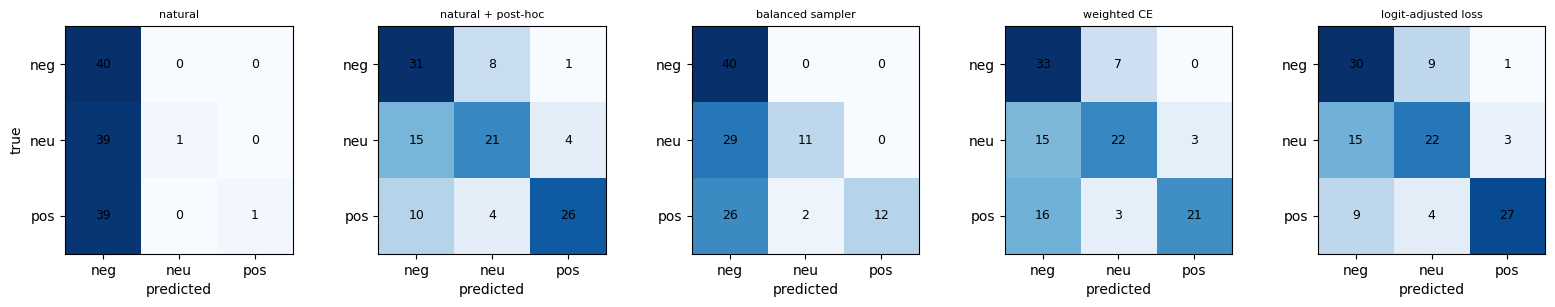

In [12]:
rows = []
for name, (y, z, _) in mini_results.items():
    m = metrics(y, z.argmax(1))
    s = z[:, 1] - z[:, 0]
    m['auc'] = auc(s[y == 1], s[y == 0])
    rows.append((name, m))
print_metrics(rows, 'mini test set (40 per class), 1 seed')
print()
for name, m in rows:
    print(f'{name:22s} AUC neutral vs negative = {m["auc"]:.3f}')

fig, ax = plt.subplots(1, len(rows), figsize=(3.2 * len(rows), 3))
for a, (name, _) in zip(ax, rows):
    y, z, _ = mini_results[name]
    cm = np.zeros((3, 3), dtype=int)
    for t, p in zip(y, z.argmax(1)):
        cm[t, p] += 1
    a.imshow(cm, cmap='Blues')
    for i in range(3):
        for j in range(3):
            a.text(j, i, cm[i, j], ha='center', va='center', fontsize=9)
    a.set_xticks(range(3), ['neg', 'neu', 'pos'])
    a.set_yticks(range(3), ['neg', 'neu', 'pos'])
    a.set_title(name, fontsize=8)
    a.set_xlabel('predicted')
ax[0].set_ylabel('true')
save_and_show(fig, '07_mini_confusion.png')

**natural sampling + plain CE collapses completely: 35.0%, every test child is called negative** (negative recall 100, neutral 2.5, positive 2.5). with 160 / 20 / 20 children the model learns "say negative", the same as step 3 predicts for an 8 : 1 prior, only more extreme.

**the 3 fixes that work on the loss or the decision all repair it to about the same level**: post-hoc adjustment (tau = 1) 65.0 (neutral 52.5), weighted CE 63.3 (neutral 55.0) and logit-adjusted loss 65.8 (neutral 55.0). that's the same "they're all about equal" result as the toy in step 5. **the balanced sampler only half-repairs it: 52.5, still 100% negative recall, neutral 27.5.** with only 20 neutral and 20 positive children shown again and again, the model can learn *those 20 children* (also because the triplet learns child identity), and new children still look "not like them", so they fall back to negative. that's the memorising risk from step 2.

**the AUC is about the same for all variants (0.79-0.81), even for the collapsed natural model (0.809).** so the natural model ranks neutral above negative just as well as the others, it only puts the border in the wrong place, which is the same thing i found in the full model (old notebook 03). here tau = 1 was fine, while on the full model (step 6) the best tau was ~0.5, so how much prior a model learns differs from model to model, and tau must be tuned.

one seed and 40 children per class, so one neutral child = 2.5 points. only the big effects (natural collapse, the 3 equal fixes, balanced sampler weaker) are worth believing.

step 8: analysis

**1. is the neutral problem of ScoNet-MT a feature problem or a prior problem?**

mostly a prior problem. a one-feature example with an 8 : 1 prior already gives the pattern of my model (neutral 26 / negative 98 vs my 40.5 / 98.5), and on my real logits only moving the border lifts the neutral recall from 32.5 to 77.9 (CV, 10 models), without touching the features.

**2. which fix is best?**

on the toy and in the mini training, weighted CE, logit-adjusted loss and post-hoc adjustment are about equal (63-66%), and the theory says they all aim at the same balanced border. the balanced sampler was weaker in the mini training (52.5), probably because it repeats the few minority children until it memorises them. the size of the correction must be tuned: on the full model the best tau was ~0.5, not 1.

**3. why is a fixed tau = 1 wrong?**

it assumes the logits contain exactly the full `log prior`. with label smoothing (0.1), cosine logits (at most 32 apart after x16) and a triplet loss pulling in another direction, a model can learn more or less of the prior. on the full model the best tau was 0.21-0.94 and different for every checkpoint, and on the mini model tau = 1 happened to work.

**4. do ScoliGaitX and TG-MILNet beat ScoNet-MT because of their architecture?**

ScoliGaitX sits on my border-moving curve, so most of its gain could be a different border (they use inverse class-weighted CE). TG-MILNet sits above the curve, so it has a real ranking gain, which fits its BAM ablation (notebook 06).

**5. what about stability?**

choosing tau per checkpoint shrinks the accuracy spread over the checkpoints from 8.6 to 2.0, so a large part of the checkpoint-to-checkpoint jumping of ScoNet-MT is the border.

**6. why did my checkpoint_1 mini models call every test child "neutral"?**

while building this notebook i found that testing with all 300 frames at once (instead of 16-frame clips like in training) ruins a mini model: 36.7% vs 65.8% on the same model, because the max over 300 frames is far bigger than anything seen in training. so part of what i saw in checkpoint_1 was a train / test mismatch, not only too few children.

**7. what are the limitations?**

- step 6 and the CV part only use the **test set** (no val split). the CV is honest about the tuning, but it's not a paper number.
- the toy data is 2D gaussians, while real features are not gaussian and the classes are not equally spread.
- the mini training is 1 seed, 200 training children with only 20 per minority class, 500 iterations and 40 test children per class. the balanced sampler result could be very different with 74 neutrals and 16,000 iterations, so it shows a risk, not a final verdict.
- the mini models start from GaitBase (gait recognition), while the full ScoNet-MT starts from random weights.
- i didn't test combinations (e.g. weighted CE + post-hoc tau tuned on val).
- Sen / Spe follow the paper convention (Sen = negative recall), which hides the neutral vs positive confusion, so i always also print the per-class recalls and the balanced accuracy.

what can we absorb into the new architecture?

the most important thing is to **keep the border correction as a separate, tuned step**: post-hoc logit adjustment with `tau` chosen on the **val split** (`checkpoint_2/experiments/exp_1`, run as `exp_2` A_base), per model. it's free, it's the biggest single gain, and it makes the checkpoints much more stable. but **never fix tau = 1**, and always report the chosen tau and the whole Sen / Spe curve.

for training i would use a **loss-side fix** (inverse-frequency weighted CE like ScoliGaitX and the DRF config, or the logit-adjusted loss) rather than a pure balanced sampler. if a balanced sampler is used, it should come with augmentation, and i have to watch for memorising (train vs val gap on neutral).

for the reporting, i should **always report the AUC next to the recall**, so a reader can see if a method ranks better (TG-MILNet) or only moves the border (ScoliGaitX-like), and compare the methods at **matched Sen** (e.g. Sen >= 97), otherwise a model that simply moved its border looks better. and last, **watch the frame count**: test with the same kind of input as in training (or train with enough frames), see question 6.